In [22]:
import argparse
import lzma
import os
import pickle
import sys
from typing import Optional
import urllib.request

import numpy as np
import numpy.typing as npt
import matplotlib.pyplot as plt

import sklearn.metrics
import sklearn.model_selection

import warnings

warnings.filterwarnings("ignore", category=sklearn.exceptions.ConvergenceWarning)


In [119]:
parser = argparse.ArgumentParser()
# These arguments will be set appropriately by ReCodEx, even if you change them.
parser.add_argument(
    "--predict", default=None, type=str, help="Path to the Dataset to predict"
)
parser.add_argument(
    "--recodex", default=False, action="store_true", help="Running in ReCodEx"
)
parser.add_argument("--seed", default=42, type=int, help="Random seed")
# For these and any other arguments you add, ReCodEx will keep your default value.
parser.add_argument(
    "--model_path", default="thyroid_competition.model", type=str, help="Model path"
)

parser.add_argument("--data_size", default=100, type=int, help="Data size")
parser.add_argument(
    "--test_size",
    default=0.5,
    type=lambda x: int(x) if x.isdigit() else float(x),
    help="Test size",
)

parser.add_argument(
    "--track_iterations",
    default=500,
    type=int,
    help="0 = disabled",
)

parser.add_argument(
    "--max_iter",
    default=500,
    type=int,
)

_StoreAction(option_strings=['--max_iter'], dest='max_iter', nargs=None, const=None, default=500, type=<class 'int'>, choices=None, required=False, help=None, metavar=None, deprecated=False)

In [120]:
class Dataset:
    """Thyroid Dataset.

    The Dataset contains real medical data related to thyroid gland function,
    classified either as normal or irregular (i.e., some thyroid disease).
    The data consists of the following features in this order:
    - 15 binary features
    - 6 real-valued features

    The target variable is binary, with 1 denoting a thyroid disease and
    0 normal function.
    """

    def __init__(
        self,
        name="thyroid_competition.train.npz",
        url="https://ufal.mff.cuni.cz/~courses/npfl129/2627/datasets/",
    ):
        if not os.path.exists(name):
            print("Downloading Dataset {}...".format(name), file=sys.stderr)
            urllib.request.urlretrieve(url + name, filename="{}.tmp".format(name))
            os.rename("{}.tmp".format(name), name)

        # Load the Dataset and return the data and targets.
        Dataset = np.load(name)
        for key, value in Dataset.items():
            setattr(self, key, value)


In [121]:
def split_cat_num_features(X: np.ndarray) -> tuple[list[int], list[int]]:
    num_col = []
    cat_col = []

    for i in range(X.shape[1]):
        if np.all(X[:, i] == X[:, i].astype(int)):
            cat_col.append(i)
        else:
            num_col.append(i)

    return num_col, cat_col

In [ ]:
def create_model_from_hyperparameters(
    hyperparams: dict,
) -> sklearn.pipeline.Pipeline:
    enc = sklearn.preprocessing.OneHotEncoder(
        sparse_output=False, handle_unknown="ignore"
    )
    scaler = sklearn.preprocessing.PowerTransformer()
    ct = sklearn.compose.ColumnTransformer(
        [
            ("categorical", enc, hyperparams["cat_cols"]),
            ("numerical", scaler, hyperparams["num_cols"]),
        ]
    )
    
    poly = sklearn.preprocessing.PolynomialFeatures()
    regres = sklearn.linear_model.LogisticRegression(
        random_state=hyperparams["seed"], max_iter=hyperparams["max_iter"],
        #class_weight="balanced"
    )

    pipe = sklearn.pipeline.Pipeline(
        [("transformer", ct), ("polynomial", poly), ("lr", regres)]
    )

    return pipe

In [138]:
def get_optimized_model(hyperparams: dict):
    pipe = create_model_from_hyperparameters(hyperparams)

    return sklearn.model_selection.GridSearchCV(
        estimator=pipe,
        param_grid={
                "polynomial__degree": [1, 2],
                "polynomial__interaction_only": [True, False],
                "lr__C": [0.1, 1, 10, 100],
                "lr__class_weight": [None, "balanced"],
            },
            cv=sklearn.model_selection.StratifiedKFold(
                n_splits=5, shuffle=True, random_state=hyperparams["seed"]
            ),
        )



In [139]:
def track_iterations(
    hyperparams: dict,
    train_data,
    train_target,
    test_data,
    test_target,
    n_iter: int = 100,
    search=None,
):
    """Track train/test accuracy of the tuned logistic regression per iteration.
 
    The model comes from `get_optimized_model`, so preprocessing and the
    hyper-parameter grid are always the same as for the final model.
    Pass the already fitted GridSearchCV as `search` to avoid running the
    grid search a second time.
    """
    if search is None:
        search = get_optimized_model(hyperparams)
        search.fit(train_data, train_target)
 
    best = search.best_estimator_  # fitted ColumnTransformer + Polynomial + LR
    preprocess = best[:-1]
    x_train = preprocess.transform(train_data)
    x_test = preprocess.transform(test_data)
 
    # Clone the tuned LR (keeps C, solver, class_weight, random_state, ...)
    # and only change it so that every .fit() call does a single iteration.
    lr = sklearn.base.clone(best["lr"]).set_params(max_iter=1, warm_start=True)
 
    train_acc, test_acc = [], []
    for _ in range(n_iter):
        lr.fit(x_train, train_target)
        train_acc.append(
            sklearn.metrics.accuracy_score(train_target, lr.predict(x_train))
        )
        test_acc.append(
            sklearn.metrics.accuracy_score(test_target, lr.predict(x_test))
        )
 
    print(
        f"Iteration {n_iter:3d}: "
        f"train acc {train_acc[-1]:.4f}, test acc {test_acc[-1]:.4f}"
    )
 
    return train_acc, test_acc



def plot_iterations(train_acc, test_acc, title: str = ""):
    iterations = range(1, len(train_acc) + 1)
    plt.figure(figsize=(8, 5))
    plt.plot(iterations, train_acc, label="train")
    plt.plot(iterations, test_acc, label="test")
    plt.xlabel("Iteration")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Accuracy: 0.9862142099681867
Best parameters: {'lr__C': 10, 'lr__class_weight': None, 'polynomial__degree': 2, 'polynomial__interaction_only': True}
Iteration 500: train acc 0.9952, test acc 0.9867


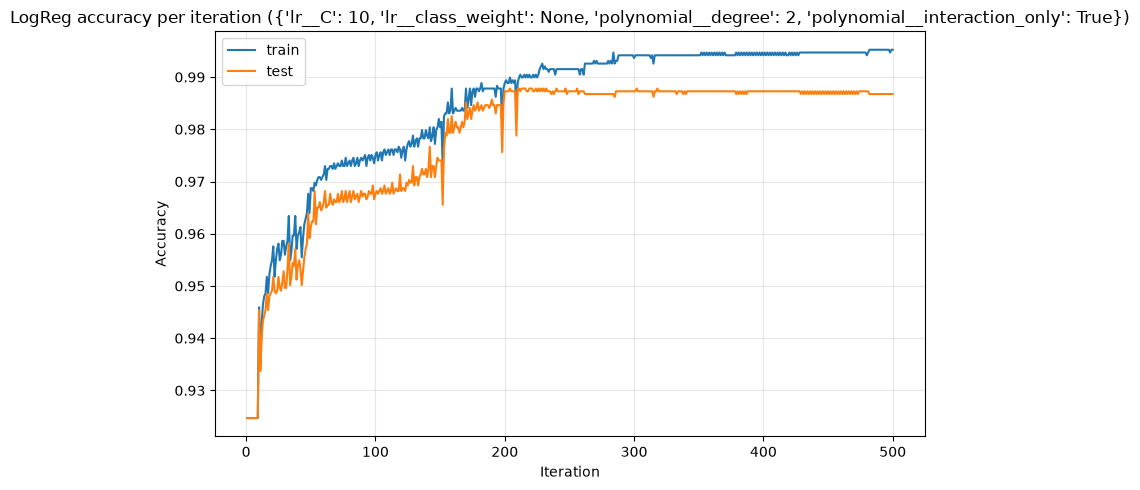

In [140]:
args = parser.parse_args([] if "__file__" not in globals() else None)

if args.predict is None:
    # We are training a model.
    np.random.seed(args.seed)
    train = Dataset()

    # TODO: Train a model on the given Dataset and store it in `model`.

    train_data, test_data, train_target, test_target = (
        sklearn.model_selection.train_test_split(
            train.data,
            train.target,
            test_size=args.test_size,
            random_state=args.seed,
            stratify=train.target
        )
    )

    hyperparams = dict()

    num_cols, cat_cols = split_cat_num_features(train_data)
    hyperparams["cat_cols"] = cat_cols
    hyperparams["num_cols"] = num_cols

    hyperparams["seed"] = args.seed
    hyperparams["max_iter"] = args.max_iter

    model = get_optimized_model(hyperparams)

    model.fit(train_data, train_target)
    y_predikce = model.predict(test_data)

    print("Accuracy:", sklearn.metrics.accuracy_score(test_target, y_predikce))
    print("Best parameters:", model.best_params_)

    if args.track_iterations > 0:
        train_acc, test_acc = track_iterations(
            hyperparams,
            train_data, train_target, test_data, test_target,
            n_iter=args.track_iterations,
            search=model,
        )
        plot_iterations(
            train_acc, test_acc,
            title=f"LogReg accuracy per iteration ({model.best_params_})",
        )



    # Serialize the model.
    with lzma.open(args.model_path, "wb") as model_file:
        pickle.dump(model, model_file)

else:
    # Use the model and return test set predictions, either as a Python list or a NumPy array.
    test = Dataset(args.predict)

    with lzma.open(args.model_path, "rb") as model_file:
        model = pickle.load(model_file)

    # TODO: Generate `predictions` with the test set predictions.
    predictions = model.predict(test.data)

[[1732   12]
 [  14  128]]
              precision    recall  f1-score   support

           0     0.9920    0.9931    0.9926      1744
           1     0.9143    0.9014    0.9078       142

    accuracy                         0.9862      1886
   macro avg     0.9531    0.9473    0.9502      1886
weighted avg     0.9861    0.9862    0.9862      1886



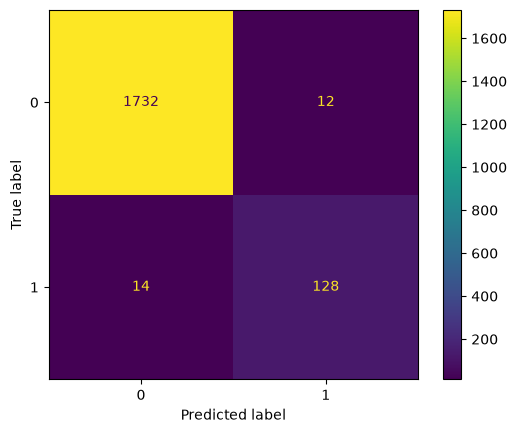

In [141]:
cm = sklearn.metrics.confusion_matrix(test_target, y_predikce)
print(cm)
print(sklearn.metrics.classification_report(test_target, y_predikce, digits=4))

sklearn.metrics.ConfusionMatrixDisplay.from_predictions(test_target, y_predikce)
plt.show()
